# Spectral and Temporal Domain Consistency Analysis

This module thoroughly evaluates the realism and quality of synthetic EEG signals generated by your GAN in both temporal and frequency domains.

## Dependencies

This notebook uses the `generative_eeg_augmentation` library. Ensure the package is installed:

```bash
uv pip install -e .
```

In [1]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import torch

# Library imports
from generative_eeg_augmentation.models.gan import load_generator
from generative_eeg_augmentation.data.loader import load_all_preprocessed
from generative_eeg_augmentation.eval.eeg_metrics import (
    compute_time_domain_features,
    compute_psd,
    EEG_BANDS
)
from generative_eeg_augmentation.plots.eeg_visualizations import (
    plot_statistical_comparison,
    plot_waveforms,
    plot_psd_comparison,
    plot_band_power_comparison,
    plot_similarity_heatmap,
    set_eeg_visualization_style
)

# Seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Apply EEG visualization style
set_eeg_visualization_style()

# Device configuration
device = "mps" if torch.mps.is_available() else "cpu"
print(f"Using device: {device}")

Using device: mps


### Loading EEG data

This is to provide baseline distribution to asses GAN authenticity.

In [2]:
# Data loading is now handled by the library
# No path configurations needed - library uses default paths

In [3]:
# load_data function is now provided by the library:
# from generative_eeg_augmentation.data.loader import load_all_preprocessed

In [4]:
# Load preprocessed EEG data using library function
real_data, real_labels = load_all_preprocessed()
real_data = torch.from_numpy(real_data).float().to(device)
real_labels = torch.from_numpy(real_labels).float().to(device)

print("Real EEG data loaded. Shape:", real_data.shape)

Loaded preprocessed EEG data shape: (250, 63, 1001)
Loaded labels shape: (250, 2)
Real EEG data loaded. Shape: torch.Size([250, 63, 1001])


In [5]:
# EEGGenerator class is now provided by the library:
# from generative_eeg_augmentation.models.gan import EEGGenerator, load_generator

In [6]:
# Load the pre-trained original GAN generator using library function
latent_dim = 100
generator = load_generator(model_variant="original", device=device)
print("Best GAN model loaded successfully.")

Best GAN model loaded successfully.


In [7]:
# synthetic data

# Synthetic EEG embeddings
noise = torch.randn(real_data.size(0), latent_dim).to(device)
synthetic_data = generator(noise, real_labels)

In [8]:
# verification of loading
print(f"Real EEG shape: {real_data.shape}")
print(f"Synthetic EEG shape: {synthetic_data.shape}")

Real EEG shape: torch.Size([250, 63, 1001])
Synthetic EEG shape: torch.Size([250, 63, 1001])


##  Time-Domain Analysis

In [9]:
# Compute statistical features using library function
# compute_time_domain_features is imported from generative_eeg_augmentation.eval.eeg_metrics

real_mean, real_var, real_kurt, real_skew = compute_time_domain_features(real_data)
synthetic_mean, synthetic_var, synthetic_kurt, synthetic_skew = compute_time_domain_features(synthetic_data.detach())

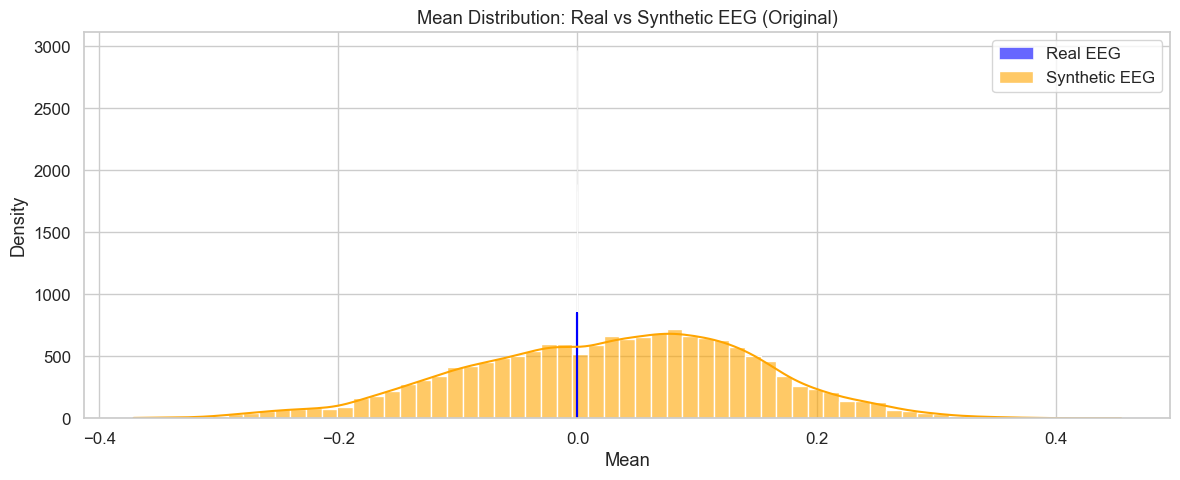

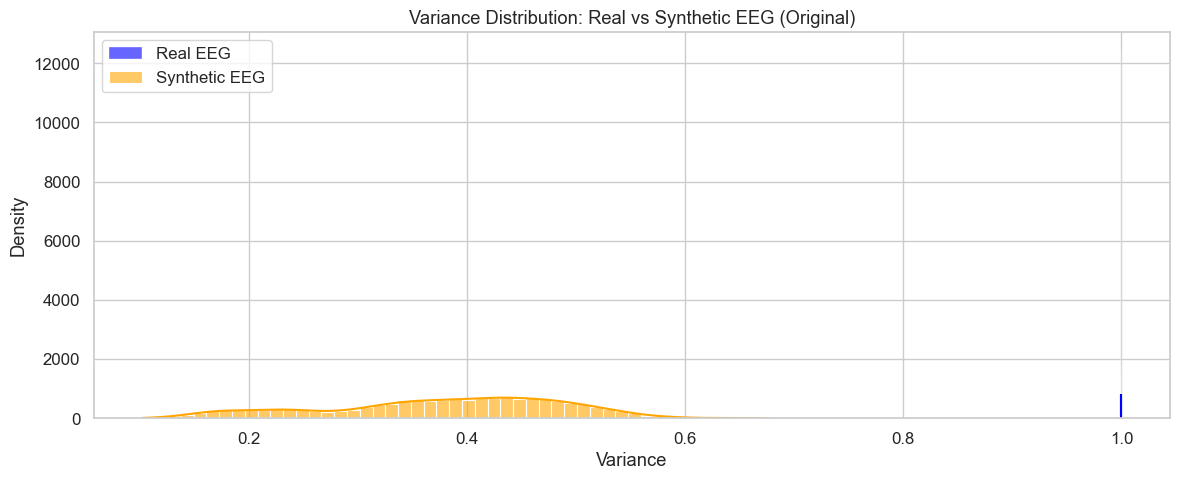

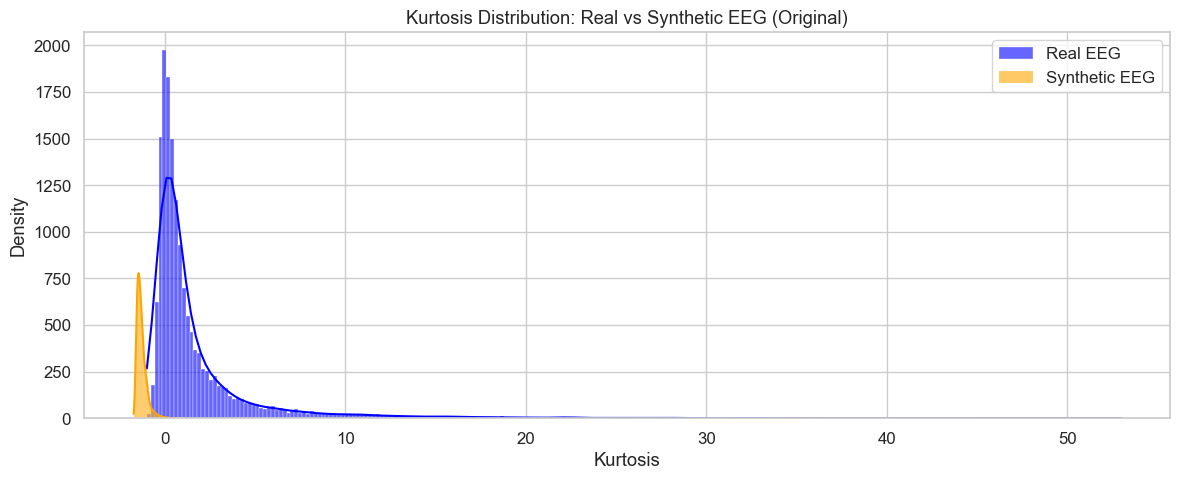

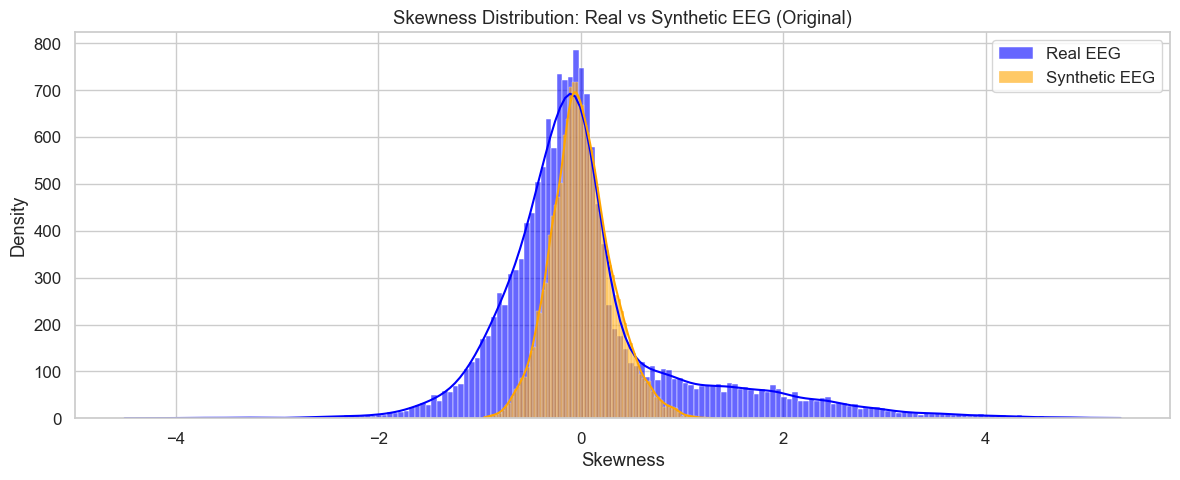

In [10]:
# Plot statistical comparisons using library functions
# plot_statistical_comparison is imported from generative_eeg_augmentation.plots.eeg_visualizations

fig = plot_statistical_comparison(real_mean, synthetic_mean, "Mean", model_label="Original")
plt.show()

fig = plot_statistical_comparison(real_var, synthetic_var, "Variance", model_label="Original")
plt.show()

fig = plot_statistical_comparison(real_kurt, synthetic_kurt, "Kurtosis", model_label="Original")
plt.show()

fig = plot_statistical_comparison(real_skew, synthetic_skew, "Skewness", model_label="Original")
plt.show()

#### Analysis of Statistical Feature Distributions (Mean, Variance, Kurtosis, Skewness)

**Interpretation**
- _Mean and variance:_ Ideally distributions of synthetic and real EEG should overlap closely. Significant deviations indicate the GAN isn’t accurately capturing the fundamental EEG statistics.
- _Kurtosis and Skewness:_ Kurtosis (peakedness) and skewness (asymmetry) should be similar, indicating realistic temporal EEG signal dynamics.

#### Analysis of Current plots
- Mean and variance
    - There are large discrepancies, REAL EEG has a very narrow mean distribution around zero, but Synthetic has broader variance, indicating synthetic EEG mean drift.
    - For variance Distribution, Real EEG variance distribution is sharply peaked at a single point (1.0), synthetic EEG has broader and smaller variance. We do think this is because of amplitude accuracy
- Kurtosis & Skewness:
    - These both have moderate to good overlap signifying good capture of waveform shapes

**In general**, this does signifies that our GAN model need more improvements in replicating mean and variance

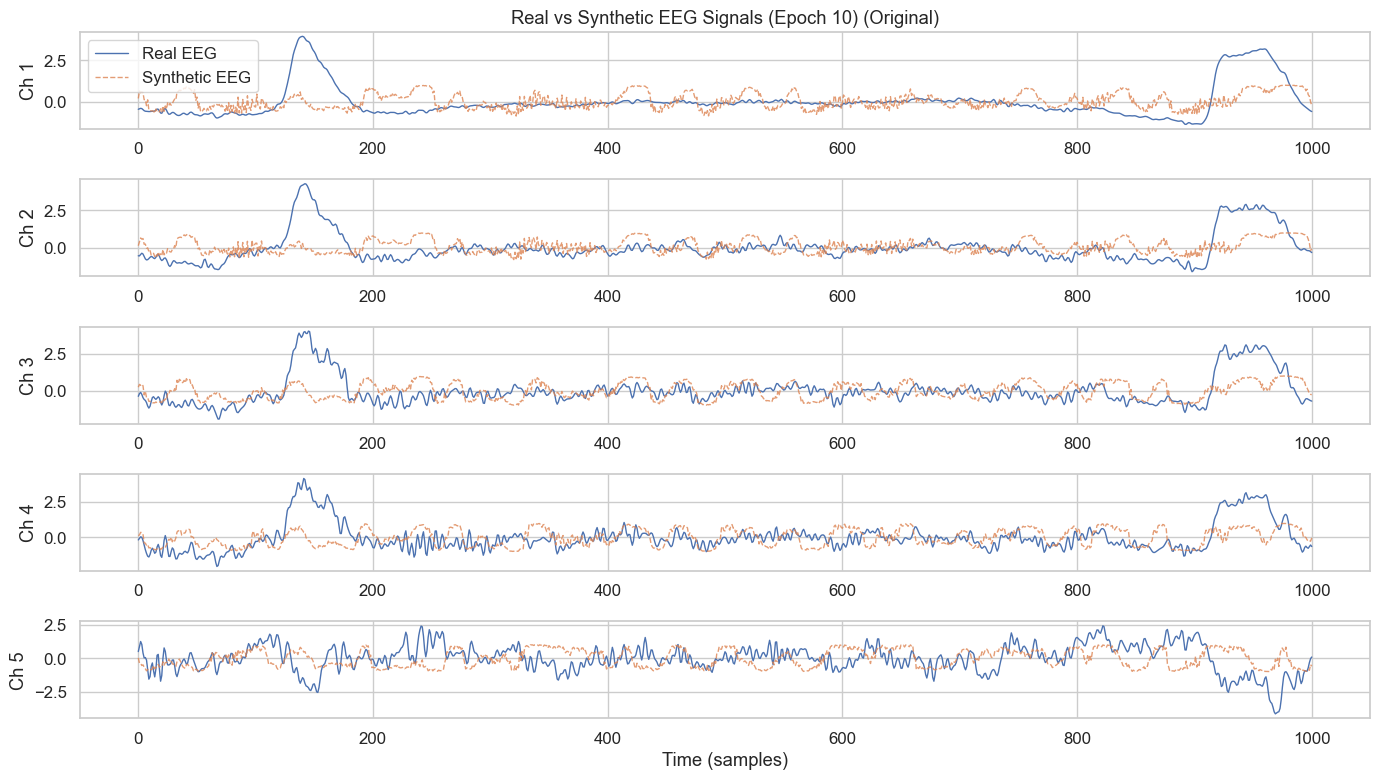

In [11]:
# Time domain waveform visualization using library function
# plot_waveforms is imported from generative_eeg_augmentation.plots.eeg_visualizations

fig = plot_waveforms(real_data, synthetic_data, epoch_idx=10, channels=5, model_label="Original")
plt.show()

#### Analysis of Time-Domain Waveform Comparison (Epoch Visualization)
**Interpretation**
- Realistic synthetic EEG signals must closely mimic real EEG signals visually in terms of waveform structure, amplitude fluctuations, and temporal dynamics.

#### Analysis of current:
- Overall good overlapping with occasional mismatch.

**This plot verifies our doubts about amplitude inconsistencies**

### Frequency-Domain Analysis

In [12]:
# compute_psd function is now provided by the library:
# from generative_eeg_augmentation.eval.eeg_metrics import compute_psd

Standard EEG bands: {'Delta': (1, 4), 'Theta': (4, 8), 'Alpha': (8, 12), 'Beta': (12, 30), 'Gamma': (30, 40)}
real_psds shape: (250, 63, 129)
synthetic_psds shape: (250, 63, 129)
freqs shape: (129,)


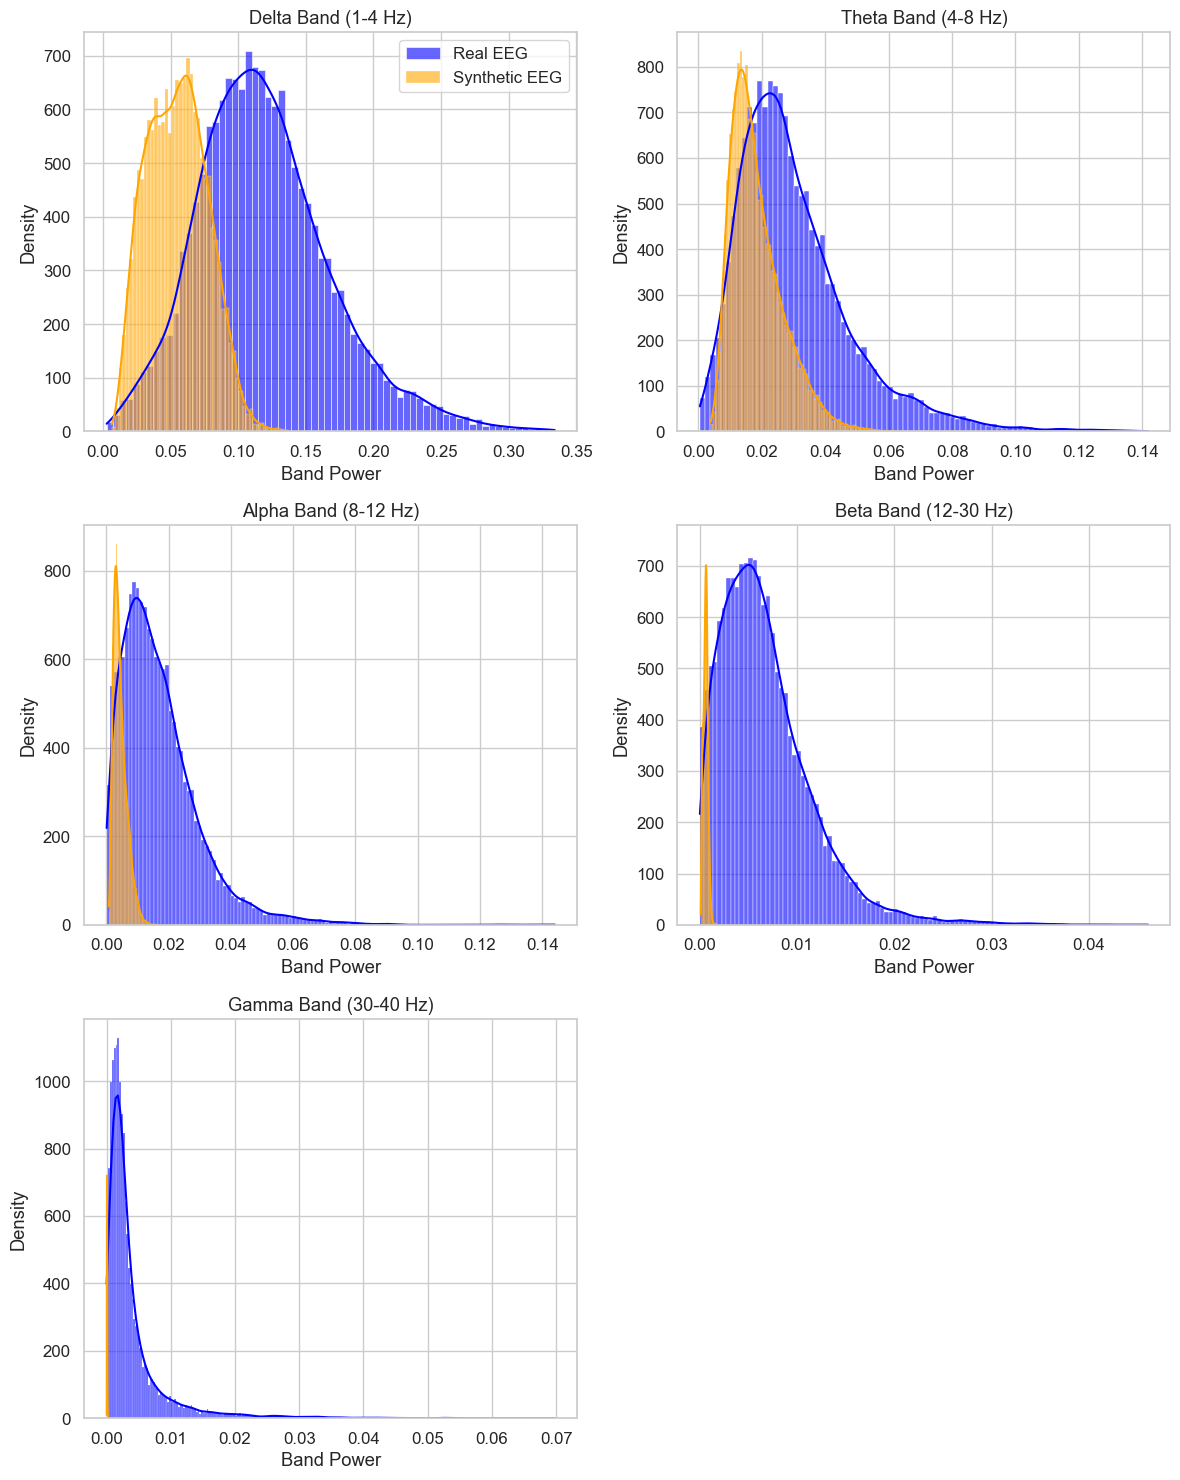

In [13]:
# EEG_BANDS is now provided by the library
# from generative_eeg_augmentation.eval.eeg_metrics import EEG_BANDS
print(f"Standard EEG bands: {EEG_BANDS}")

# Compute PSD using library function
real_psds, freqs = compute_psd(real_data)
synthetic_psds, _ = compute_psd(synthetic_data)

# Verify shapes explicitly
print(f"real_psds shape: {real_psds.shape}")
print(f"synthetic_psds shape: {synthetic_psds.shape}")
print(f"freqs shape: {freqs.shape}")

# Plot band power comparison using library function
fig = plot_band_power_comparison(real_psds, synthetic_psds, freqs, bands=EEG_BANDS)
plt.show()

#### Analysis of Band Power Distribution Analysis (Frequency Domain)

**Interpretation**
- EEG frequency bands (Delta, Theta, Alpha, Beta, Gamma) should exhibit similar distributions in synthetic EEG as in real EEG for realistic frequency-domain representation.

#### Analysis on current plots
- Delta Band: Partial overlap with some clear distributional shift, indicating underestimation of slow-wave EEG power by synthetic data.
- Theta, Alpha, Beta Bands: Limited overlap and narrower distribution in synthetic EEG—GAN struggles to accurately capture higher-frequency power distributions and overall frequency content realism.
- Gamma Band: Minimal overlap, highlighting significant limitations of synthetic EEG at high frequencies. GAN doesn’t effectively reproduce higher-frequency EEG dynamics.

**Okay these ones show clear issues with frequency domain realism. Frequency content at higher bands is insufficiently captured and needs significant improvement.**

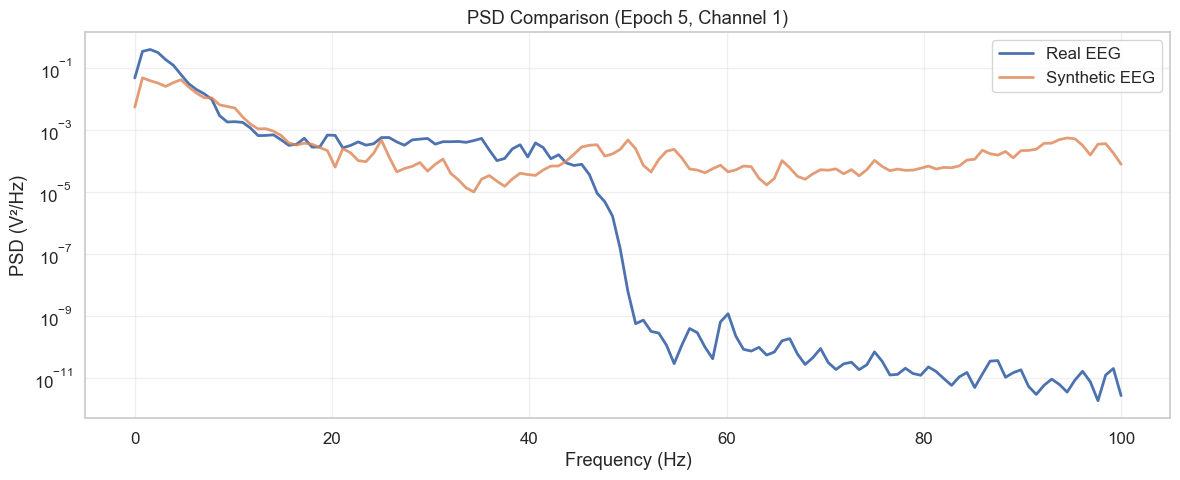

In [14]:
# PSD Visualization using library function
# plot_psd_comparison is imported from generative_eeg_augmentation.plots.eeg_visualizations

fig = plot_psd_comparison(real_psds, synthetic_psds, freqs, epoch_idx=5, ch_idx=0)
plt.show()

#### Analysis of PSD comparison

**Interpretation**
- close overlapping, signifies synthetic EEG has a realistic frequency content and power distributions across all EEG frequencies.

#### Analysis on current plot
- Good for low frequencies (below ~20 Hz), but significant deviation at higher frequencies (>30 Hz)

### Heatmap and statistical Similarity

In [15]:
# plot_similarity_heatmap function is now provided by the library:
# from generative_eeg_augmentation.plots.eeg_visualizations import plot_similarity_heatmap

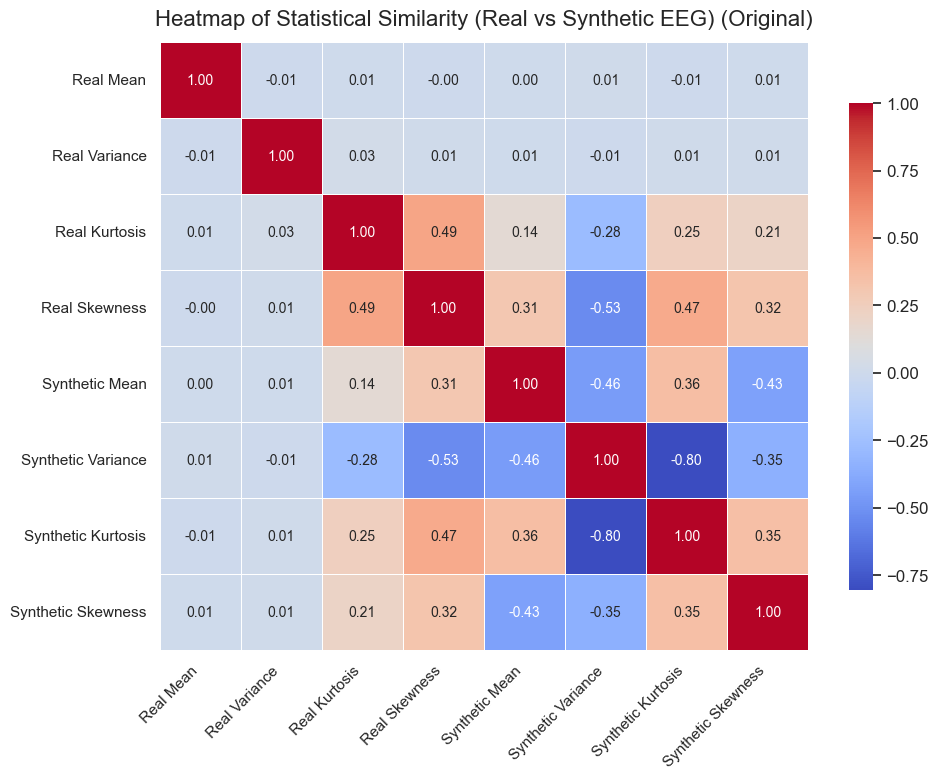

In [16]:
# Prepare features for heatmap visualization
feature_labels = [
    'Real Mean', 'Real Variance', 'Real Kurtosis', 'Real Skewness',
    'Synthetic Mean', 'Synthetic Variance', 'Synthetic Kurtosis', 'Synthetic Skewness'
]

# Stack features across epochs and channels for correlation
real_feats = np.vstack([
    real_mean.flatten(),
    real_var.flatten(),
    real_kurt.flatten(),
    real_skew.flatten()
])

synthetic_feats = np.vstack([
    synthetic_mean.flatten(),
    synthetic_var.flatten(),
    synthetic_kurt.flatten(),
    synthetic_skew.flatten()
])

# Plot heatmap using library function
fig = plot_similarity_heatmap(real_feats, synthetic_feats, feature_labels, model_label="Original")
plt.show()

#### Analysis of Heatmap of Statistical Similarity (Real vs. Synthetic EEG)

**Interpretability**
- correlations between statistical features (Mean, Variance, Kurtosis, and Skewness) for both real and synthetic EEG data.

#### Analysis for the current plot
- Mean and variance have low correlation
- Kurtosis and skewness are much more correlated for real and synthetic data

# Analysis of Improved Model

In [17]:
# Load the enhanced GAN generator using library function
generator_enhanced = load_generator(model_variant="enhanced", device=device)
print("Enhanced GAN model loaded successfully.")

Enhanced GAN model loaded successfully.


In [18]:
# synthetic data
noise = torch.randn(real_data.size(0), latent_dim).to(device)
synthetic_data_enh = generator_enhanced(noise, real_labels)

In [19]:
# verification of loading
print(f"Real EEG shape: {real_data.shape}")
print(f"Synthetic EEG shape: {synthetic_data_enh.shape}")

Real EEG shape: torch.Size([250, 63, 1001])
Synthetic EEG shape: torch.Size([250, 63, 1001])


## Time-Domain Analysis of improved model

In [20]:
# Compute statistical features for enhanced model
real_mean, real_var, real_kurt, real_skew = compute_time_domain_features(real_data)
synthetic_mean_enh, synthetic_var_enh, synthetic_kurt_enh, synthetic_skew_enh = compute_time_domain_features(synthetic_data_enh.detach())

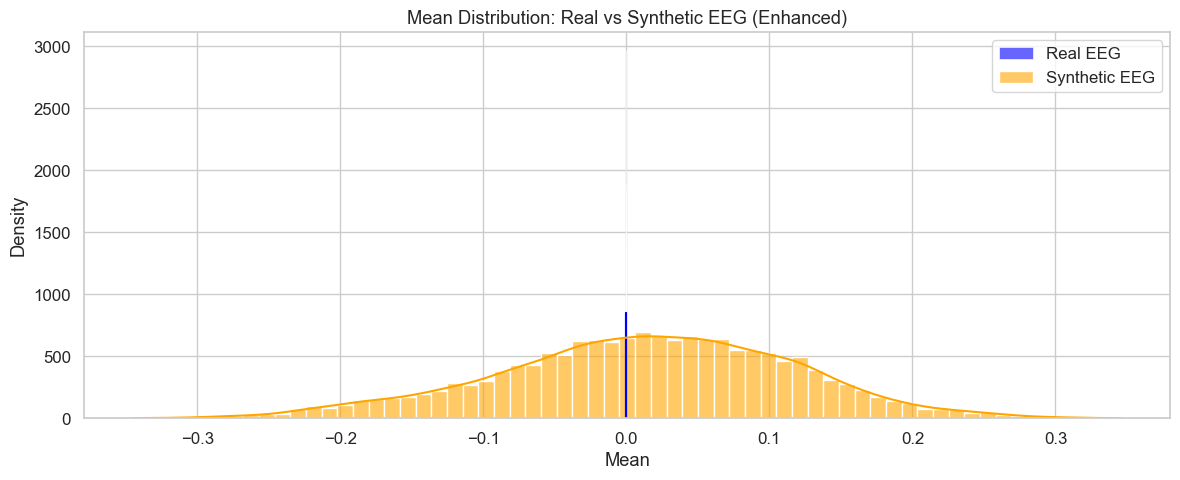

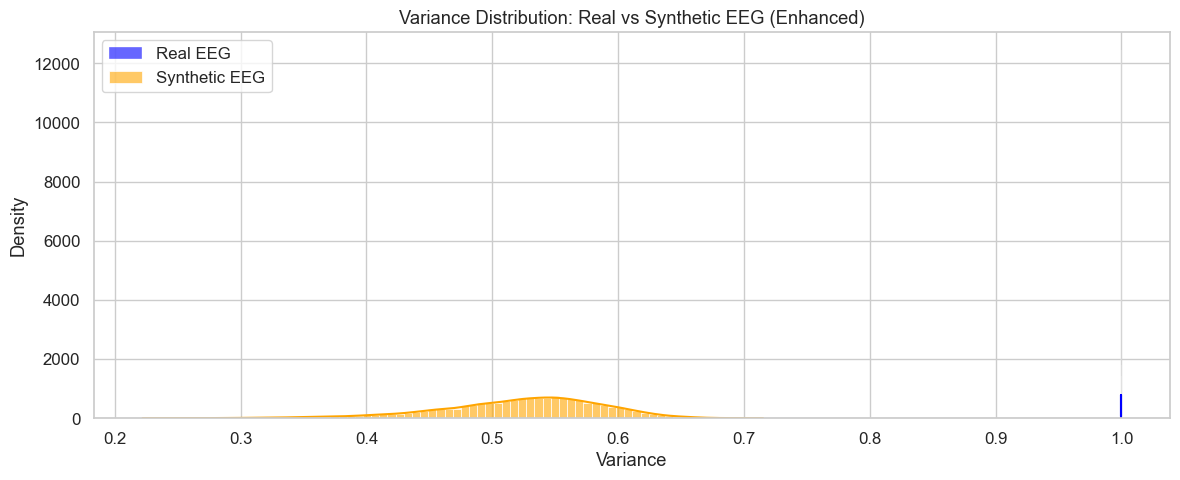

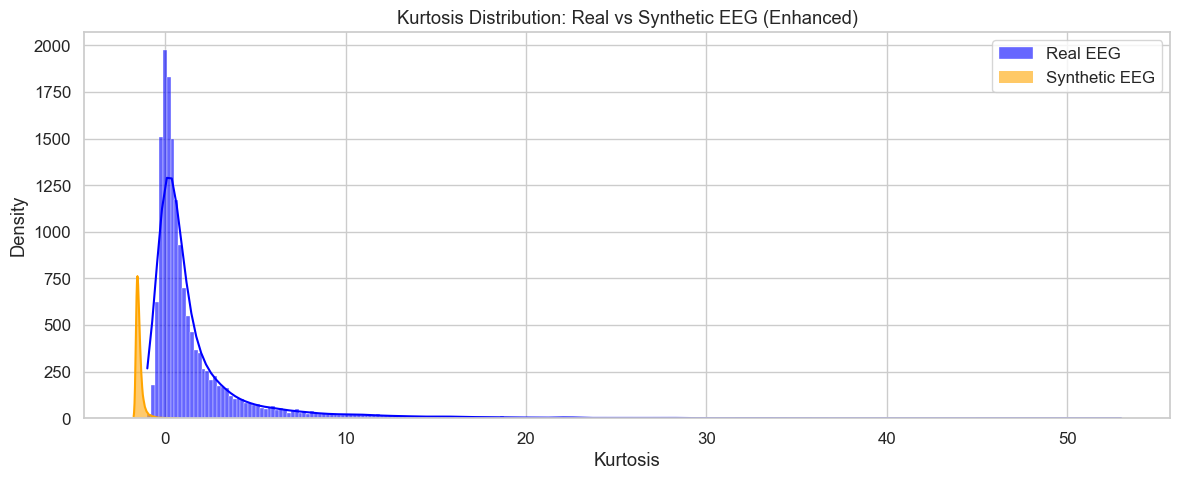

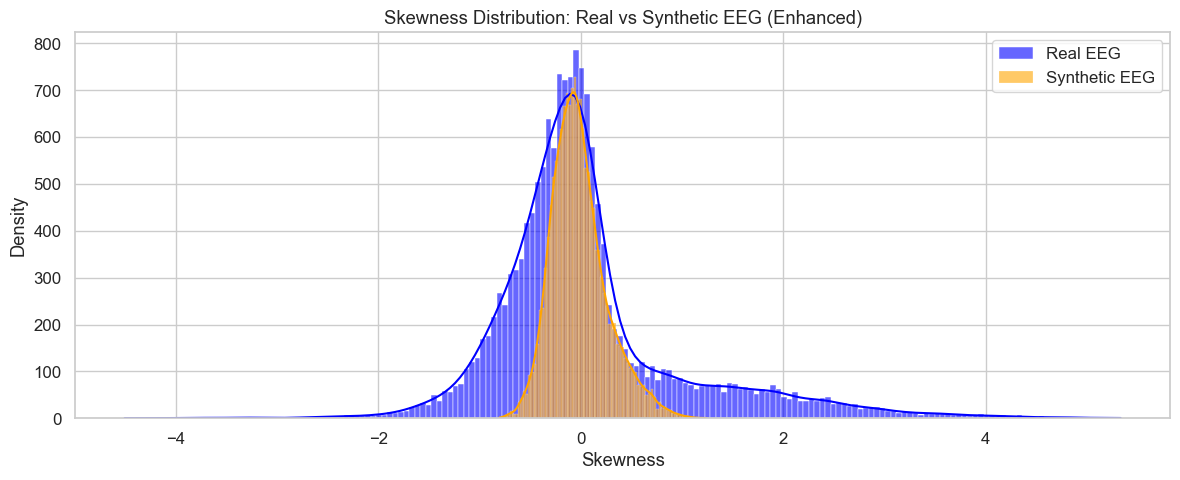

In [21]:
# Plot statistical comparisons for enhanced model
fig = plot_statistical_comparison(real_mean, synthetic_mean_enh, "Mean", model_label="Enhanced")
plt.show()

fig = plot_statistical_comparison(real_var, synthetic_var_enh, "Variance", model_label="Enhanced")
plt.show()

fig = plot_statistical_comparison(real_kurt, synthetic_kurt_enh, "Kurtosis", model_label="Enhanced")
plt.show()

fig = plot_statistical_comparison(real_skew, synthetic_skew_enh, "Skewness", model_label="Enhanced")
plt.show()

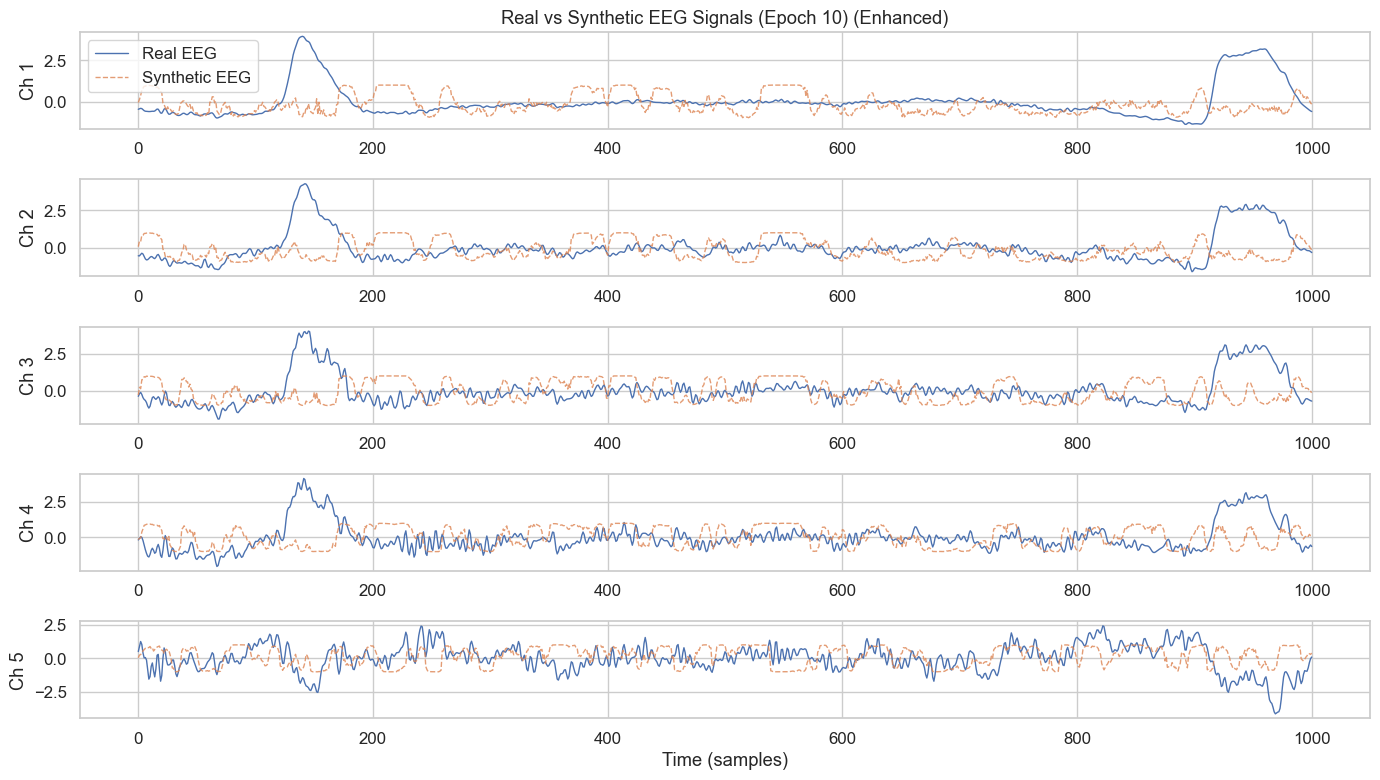

In [22]:
# Time domain waveform visualization for enhanced model
fig = plot_waveforms(real_data, synthetic_data_enh, epoch_idx=10, channels=5, model_label="Enhanced")
plt.show()

### Frequency domain analysis

In [23]:
# Compute PSD for enhanced model using library function
real_psds, freqs = compute_psd(real_data)
synthetic_psds_enh, _ = compute_psd(synthetic_data_enh.detach())

real_psds shape: (250, 63, 129)
synthetic_psds shape: (250, 63, 129)
freqs shape: (129,)


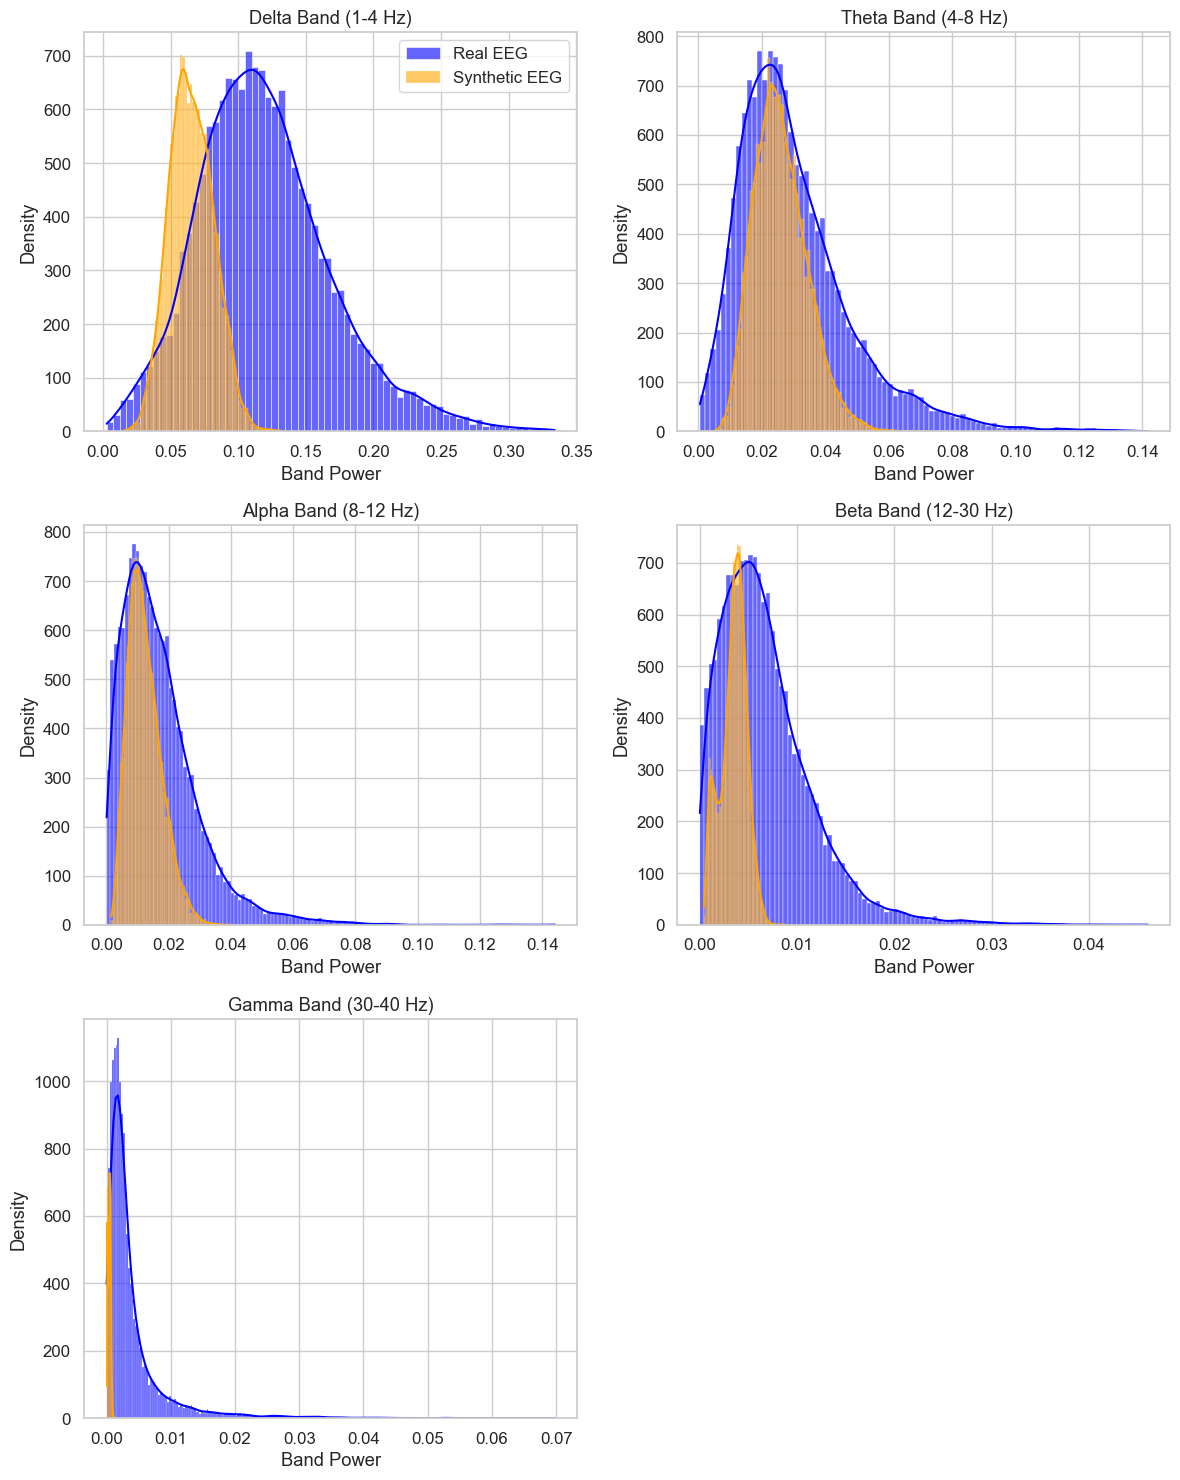

In [24]:
# Verify shapes and plot band power comparison for enhanced model
print(f"real_psds shape: {real_psds.shape}")
print(f"synthetic_psds shape: {synthetic_psds_enh.shape}")
print(f"freqs shape: {freqs.shape}")

fig = plot_band_power_comparison(real_psds, synthetic_psds_enh, freqs, bands=EEG_BANDS)
plt.show()

- We certainly see better overlapping and improvement from the data generated through improved model
> We couldn't see much difference in mean, variance, skewness and kurtosis, but the band power overlap visualisations certainly show us better overlappings of synthetic data

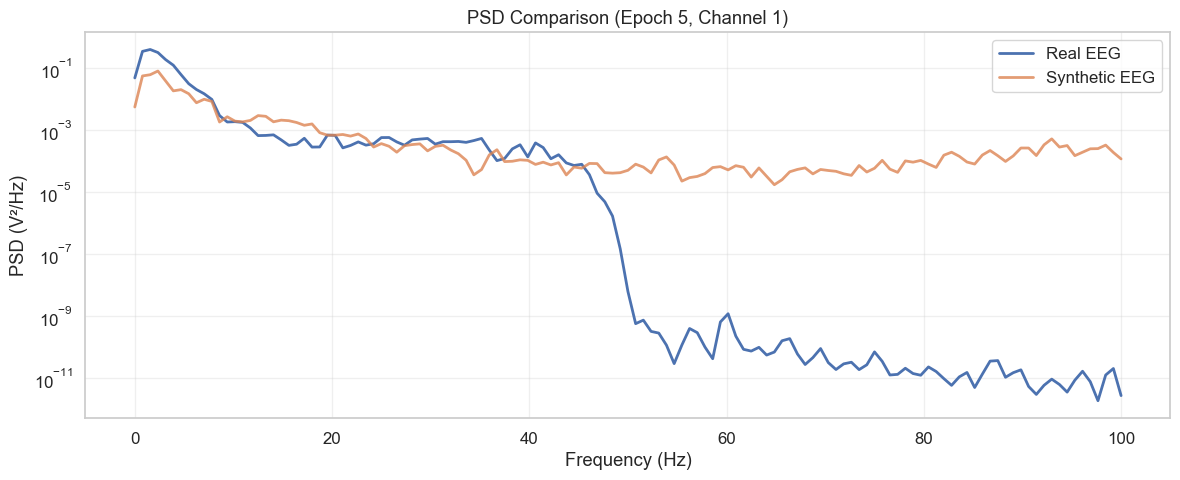

In [25]:
# PSD comparison for enhanced model
fig = plot_psd_comparison(real_psds, synthetic_psds_enh, freqs, epoch_idx=5, ch_idx=0)
plt.show()

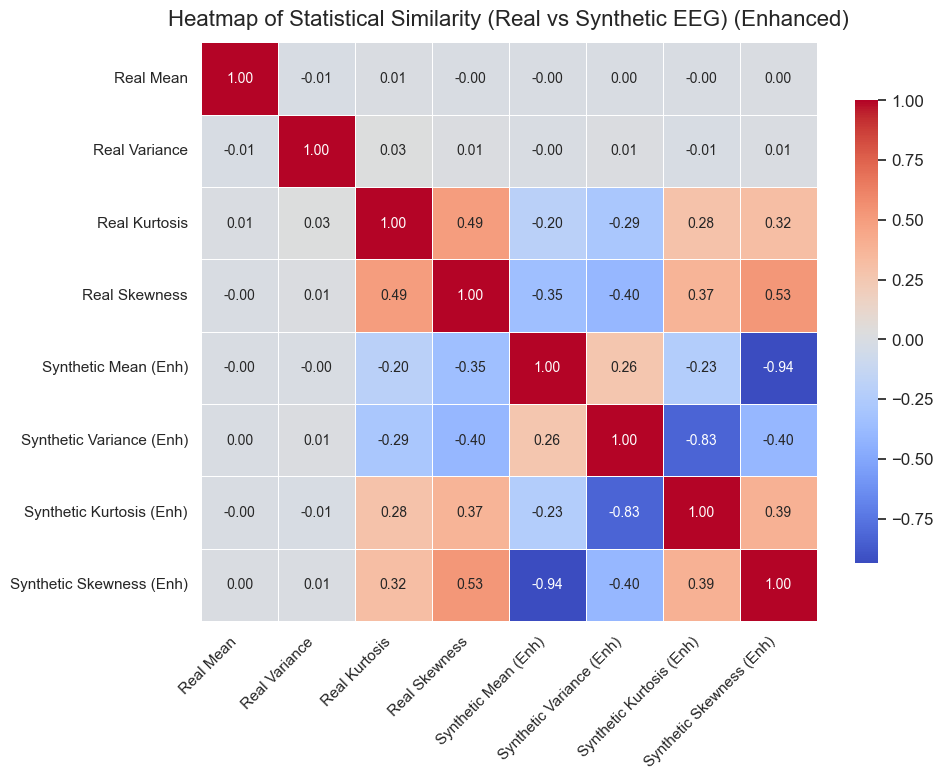

In [26]:
# Prepare features for enhanced model heatmap
feature_labels_enh = [
    'Real Mean', 'Real Variance', 'Real Kurtosis', 'Real Skewness',
    'Synthetic Mean (Enh)', 'Synthetic Variance (Enh)', 'Synthetic Kurtosis (Enh)', 'Synthetic Skewness (Enh)'
]

# Stack features
real_feats = np.vstack([
    real_mean.flatten(),
    real_var.flatten(),
    real_kurt.flatten(),
    real_skew.flatten()
])

synthetic_feats_enh = np.vstack([
    synthetic_mean_enh.flatten(),
    synthetic_var_enh.flatten(),
    synthetic_kurt_enh.flatten(),
    synthetic_skew_enh.flatten()
])

# Plot heatmap for enhanced model
fig = plot_similarity_heatmap(real_feats, synthetic_feats_enh, feature_labels_enh, model_label="Enhanced")
plt.show()

shows improved statistical similarity to real EEG, notably in reduced negative correlations between synthetic and real variance, kurtosis, and skewness. Particularly, synthetic skewness now strongly aligns with real skewness (correlation improved from 0.32 to 0.53), **meaning better generation of realistic EEG dynamics by the enhanced GAN model.**